# v11 — Per-Writer Covariance Metric Estimation for One-Class Signature Verification

### Why this notebook exists

v9 and v10 both tested *per-writer metric estimation* as a **diagonal** re-weighting of a 17-component
dissimilarity representation. Both retained H₁ (no significant gain over a global metric) on all three
corpora. This notebook asks **why**, and the answer turns out to be that the diagonal family was the
wrong family.

### What this notebook establishes

| # | Finding | Status |
|---|---|---|
| **F1** | The 17 dissimilarity components are **not independent** — participation ratio 2.38; 5 of 17 reach 95% variance | measured |
| **F2** | At n=12 enrolled signatures, a per-writer **diagonal** estimate has reliability 0.48 — half of it is noise | measured |
| **F3** | Replacing the diagonal metric with a **pooled full-covariance (Mahalanobis)** metric gains **+0.0586 AUC**, 95% CI [+0.040, +0.078], p = 8.3×10⁻¹⁰ — *writer-independent* | **H₁ rejected** |
| **F4** | A writer's **own** full covariance beats a **random other writer's** covariance (+0.0513, p = 4.6×10⁻⁴; Holm-significant on Bengali and Hindi) — the covariance carries genuinely **writer-specific** information | **H₁ rejected** |
| **F5** | A **rank-1** per-writer covariance (one free parameter) beats the pooled global metric by +0.0058, 95% CI [+0.0036, +0.0081]; Holm-significant on Bengali (p=0.013) and Hindi (p=0.00034) | **H₁ rejected** |
| **F6** | An honest oracle (metric chosen on one half of the test queries, scored on the other) reaches **+0.0396** over the global metric, p = 1.1×10⁻⁶ — real headroom no current estimator reaches | measured |

### What this notebook does *not* claim

- The full rank-17 per-writer covariance **does not** beat the pooled global metric (+0.0062, p = 0.84). The
  writer-specific information is real (F4) but the 153-parameter estimate is too noisy at n=12 to convert it
  into accuracy.
- The rank-1 gain in F5 is **small**: 53 writers improve, 13 degrade, 76 are unchanged. It is statistically
  reliable, not practically large.
- Nothing here is measured on the 172 **reserved** writers. `RUN_CONFIRMATION` stays `False` until the
  design is frozen.

> **Scope note.** All numbers below are on the 142 **development** writers only, using the same split seed
> as v9/v10 so that every figure is directly comparable to the earlier notebooks. Section 2 asserts this.

## 1 · Configuration

In [1]:
import os, re, sys, json, time, itertools, hashlib, warnings
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")

# ---- frozen experimental constants (identical to v9/v10 - do not change) ----
EPS          = 1e-9
SPLIT_SEED   = 20261014     # writer-level dev/reserved split
DEV_FRACTION = 0.45
N_ENROL      = 12           # enrolled genuine signatures per writer
N_TEST_GEN   = 12
N_TEST_FOR   = 12
NU           = 0.10         # OneClassSVM outlier-fraction bound
GAMMA        = "scale"

# ---- v11 knobs ----
RANK_GRID        = [1, 2, 3, 5, 8, 12, 17]   # rank-r per-writer covariance
LAMBDA_GRID      = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
N_BOOT           = 10000
N_ORACLE_CAND    = 200
N_ORACLE_SPLITS  = 8
RUN_ORACLE       = True     # Section 9 is the slowest part (~3 min); set False to skip
RUN_CONFIRMATION = False    # <-- LEAVE FALSE. Reserved writers are spent only once, on the final design.

PC = ["L1","L2","Linf","cosine","correlation","canberra","braycurtis","absdiff_std",
      "absdiff_median","absdiff_p90","d_mean","d_std","d_max","d_energy","chi2",
      "hist_inter","d_sum"]
NDIM = len(PC)
print(f"{NDIM} dissimilarity components; {N_ENROL} enrolled -> {N_ENROL*(N_ENROL-1)//2} enrolment pairs per writer")

17 dissimilarity components; 12 enrolled -> 66 enrolment pairs per writer


## 2 · Load features and reproduce the v9/v10 split

v11 re-uses the HOG features already extracted in v9 (`v9_features.npz`). Nothing about feature
extraction changes here — this notebook is entirely about the **metric** applied to the dissimilarity
representation, so re-extracting would only add a 20-minute step that cannot change any result.

The resolver is local-first, with a Colab fallback, and matches folders by prefix.

In [2]:
def resolve_base(candidates, label):
    """Local-first path resolution with prefix matching; falls back to Colab Drive."""
    for c in candidates:
        if c and os.path.exists(c):
            print(f"  [{label}] -> {c}")
            return c
    # prefix match inside the parents of each candidate
    for c in candidates:
        if not c: continue
        parent, stem = os.path.dirname(c), os.path.basename(c).lower()
        if os.path.isdir(parent):
            for d in sorted(os.listdir(parent)):
                if d.lower().startswith(stem[:6]) and os.path.isdir(os.path.join(parent, d)):
                    p = os.path.join(parent, d); print(f"  [{label}] prefix-matched -> {p}")
                    return p
    try:
        from google.colab import drive
        if not os.path.exists("/content/drive"): drive.mount("/content/drive")
        for c in ["/content/drive/MyDrive/4buwan", "/content/drive/MyDrive"]:
            if os.path.exists(c):
                print(f"  [{label}] colab -> {c}"); return c
    except Exception:
        pass
    raise FileNotFoundError(f"[{label}] none of these exist:\n  " + "\n  ".join(map(str, candidates)))

FEAT_NPZ = None
for cand in [r"v9_features.npz",
             r"C:\Users\ogrla\Downloads\v9_features.npz",
             r"C:\Users\ogrla\Downloads\4buwan\v9_features.npz",
             os.path.expanduser("~/Downloads/v9_features.npz"),
             "/content/drive/MyDrive/4buwan/v9_features.npz"]:
    if os.path.exists(cand): FEAT_NPZ = cand; break
if FEAT_NPZ is None:
    raise FileNotFoundError("v9_features.npz not found. Put it next to this notebook.")
print("features:", FEAT_NPZ)

_z = np.load(FEAT_NPZ, allow_pickle=True)
FEATURES = {k: _z[k].item() for k in _z.keys()}
print("feature blocks:", list(FEATURES.keys()), "| images:", len(FEATURES["HOG"]))

features: C:\Users\ogrla\Downloads\v9_features.npz
feature blocks: ['HOG', 'RAW', 'CTRL'] | images: 11304


In [3]:
# ---- manifest: parse corpus / writer / genuine-vs-forged / index out of the stored paths ----
RE_CEDAR = re.compile(r"^(original|forgeries)[_-](\d+)[_-](\d+)", re.I)
RE_BHSIG = re.compile(r"^([BH])-S-(\d+)-([GF])-(\d+)", re.I)

def corpus_of(p):
    q = p.replace("\\", "/").lower()
    return "CEDAR" if "/cedar" in q else "Hindi" if "hindi" in q else "Bengali" if "bengali" in q else None

rows = []
for p in FEATURES["HOG"]:
    stem = os.path.splitext(os.path.basename(p.replace("\\", "/")))[0]
    c = corpus_of(p)
    m = RE_CEDAR.match(stem)
    if m:
        rows.append(dict(corpus=c, writer=f"{c}-{int(m.group(2)):03d}",
                         label="genuine" if m.group(1).lower() == "original" else "forged",
                         index=int(m.group(3)), path=p)); continue
    m = RE_BHSIG.match(stem)
    if m:
        rows.append(dict(corpus=c, writer=f"{c}-{int(m.group(2)):03d}",
                         label="genuine" if m.group(3).upper() == "G" else "forged",
                         index=int(m.group(4)), path=p))
MF = pd.DataFrame(rows)
assert len(MF) > 0, "manifest empty - the filename patterns did not match"

_rng = np.random.RandomState(SPLIT_SEED); _dev = []
for c, g in MF.groupby("corpus"):
    ws = np.array(sorted(g.writer.unique()))
    _dev.extend(ws[_rng.permutation(len(ws))[:max(2, int(round(DEV_FRACTION*len(ws))))]].tolist())
_dev = set(_dev)
MF["split"] = np.where(MF.writer.isin(_dev), "dev", "reserved")

SETS = {}
for (c, w), g in MF.groupby(["corpus", "writer"]):
    gen = g[g.label == "genuine"].sort_values("index").path.tolist()
    fo  = g[g.label == "forged"].sort_values("index").path.tolist()
    en, tg, tf = gen[:N_ENROL], gen[N_ENROL:N_ENROL+N_TEST_GEN], fo[:N_TEST_FOR]
    if len(en) == N_ENROL and tg and tf:
        SETS[(c, w, g.split.iloc[0])] = (en, tg, tf)

DEV      = sorted([k for k in SETS if k[2] == "dev"])
RESERVED = sorted([k for k in SETS if k[2] == "reserved"])
CORPORA  = sorted({k[0] for k in DEV})
print(f"usable writers: {len(DEV)} dev, {len(RESERVED)} reserved")
print(MF[MF.writer.isin([k[1] for k in DEV])].groupby("corpus").writer.nunique().to_string())

usable writers: 142 dev, 172 reserved
corpus
Bengali    45
CEDAR      25
Hindi      72


### 2.1 · Pair descriptor (17 symmetric components) — unchanged from v9

In [4]:
def pair_descriptor(a, b):
    """Symmetric 17-component dissimilarity between two feature vectors. Identical to v9."""
    a = np.asarray(a, float); b = np.asarray(b, float); d = np.abs(a - b)
    na, nb = np.linalg.norm(a), np.linalg.norm(b)
    cos = 1 - float(a @ b) / (na*nb + EPS)
    ac, bc = a - a.mean(), b - b.mean()
    cor = 1 - float(ac @ bc) / (np.linalg.norm(ac)*np.linalg.norm(bc) + EPS)
    return np.array([
        d.mean(), np.sqrt((d**2).sum()), d.max(), cos, cor,
        float(np.sum(d / (np.abs(a) + np.abs(b) + EPS))),
        float(d.sum() / (np.abs(a + b).sum() + EPS)),
        d.std(), np.median(d), np.percentile(d, 90),
        abs(a.mean() - b.mean()), abs(a.std() - b.std()),
        abs(a.max() - b.max()), abs((a**2).sum() - (b**2).sum()),
        float(np.sum(d**2 / (np.abs(a) + np.abs(b) + EPS))),
        1 - float(np.minimum(np.abs(a), np.abs(b)).sum()) / (max(np.abs(a).sum(), np.abs(b).sum()) + EPS),
        abs(a.sum() - b.sum())], float)

PAIR_IDX = np.array(list(itertools.combinations(range(N_ENROL), 2)))   # which 2 signatures made each pair
print("pair index shape:", PAIR_IDX.shape)

pair index shape: (66, 2)


### 2.2 · Cache the per-writer descriptor matrices

For each writer this stores

- `P` — (66 × 17) the enrolment pairs, which is what every metric is estimated from;
- `Qg`, `Qf` — (12 × 12 × 17) each test query paired against all 12 enrolled signatures.

Cached to `v11_desc.npz` so re-running any later section is instant.

In [5]:
DESC_CACHE = "v11_desc.npz"

def enrol_pairs(vecs):
    return np.array([pair_descriptor(vecs[i], vecs[j]) for i, j in PAIR_IDX])
def query_pairs(q, vecs):
    return np.array([pair_descriptor(q, v) for v in vecs])

def build_descriptors(keys, cache=None):
    if cache and os.path.exists(cache):
        z = np.load(cache)
        have = {str(s) for s in z["KEYS"]}
        if have == {f"{k[0]}|{k[1]}" for k in keys}:
            print(f"  loaded cache {cache}")
            return {(k.split('|')[0], k.split('|')[1]):
                    (z[f"{k}|P"], z[f"{k}|Qg"], z[f"{k}|Qf"]) for k in have}
    out, t0 = {}, time.time()
    for n, k in enumerate(keys):
        en, tg, tf = SETS[k]
        V  = [FEATURES["HOG"][p] for p in en]
        out[(k[0], k[1])] = (enrol_pairs(V),
                             np.array([query_pairs(FEATURES["HOG"][q], V) for q in tg]),
                             np.array([query_pairs(FEATURES["HOG"][q], V) for q in tf]))
        if n % 25 == 0: print(f"  {n}/{len(keys)}  {time.time()-t0:.0f}s", flush=True)
    if cache:
        flat = {}
        for (c, w), (P, Qg, Qf) in out.items():
            flat[f"{c}|{w}|P"] = P; flat[f"{c}|{w}|Qg"] = Qg; flat[f"{c}|{w}|Qf"] = Qf
        flat["KEYS"] = np.array([f"{c}|{w}" for (c, w) in out])
        np.savez_compressed(cache, **flat)
        print(f"  cached -> {cache}  ({time.time()-t0:.0f}s)")
    return out

DESC = build_descriptors(DEV, DESC_CACHE)
WKEYS = sorted(DESC.keys())
print(f"{len(WKEYS)} writers cached; P shape {DESC[WKEYS[0]][0].shape}, Qg shape {DESC[WKEYS[0]][1].shape}")

  0/142  0s
  25/142  4s
  50/142  7s
  75/142  10s
  100/142  13s
  125/142  16s
  cached -> v11_desc.npz  (18s)
142 writers cached; P shape (66, 17), Qg shape (12, 12, 17)


### 2.3 · Global reference statistics

`GLOBAL_SPREAD` is the per-component standard deviation pooled over **all** dev writers' enrolment pairs.
It is the common standardisation every condition starts from, so that "metric" means only what is applied
*after* standardisation. `SIGMA_POOLED` is the average within-writer covariance in that standardised space
— the pooled global full-covariance metric.

In [6]:
P_ALL = np.vstack([DESC[k][0] for k in WKEYS])
GLOBAL_SPREAD = P_ALL.std(0) + EPS

Z_W = {k: (DESC[k][0] - DESC[k][0].mean(0)) / GLOBAL_SPREAD for k in WKEYS}   # standardised, writer-centred
SIGMA_W = {k: np.cov(Z_W[k].T, bias=True) for k in WKEYS}
SIGMA_POOLED = sum(SIGMA_W.values()) / len(WKEYS)

_ev, _V = np.linalg.eigh(SIGMA_POOLED)
_o = np.argsort(_ev)[::-1]
POOL_EVAL, POOL_EVEC = _ev[_o], _V[:, _o]       # pooled eigenbasis, used by the rank-r estimator
print("pooled covariance eigenvalues:", np.round(POOL_EVAL, 3))

pooled covariance eigenvalues: [ 5.582e+00  1.603e+00  9.830e-01  7.420e-01  2.730e-01  2.470e-01
  7.900e-02  5.600e-02  2.400e-02  1.700e-02  1.000e-02  4.000e-03
  1.000e-03  1.000e-03  0.000e+00  0.000e+00 -0.000e+00]


### 2.4 · Consistency assert — this notebook must reproduce v9's published numbers

In [7]:
from sklearn.svm import OneClassSVM
from sklearn.metrics import roc_auc_score

def _fit_score(P, Qg, Qf, transform):
    mu = P.mean(0)
    T  = lambda X: transform(X - mu)
    m  = OneClassSVM(kernel="rbf", nu=NU, gamma=GAMMA).fit(T(P))
    sg = m.decision_function(T(Qg.reshape(-1, NDIM))).reshape(Qg.shape[:2]).mean(1)
    sf = m.decision_function(T(Qf.reshape(-1, NDIM))).reshape(Qf.shape[:2]).mean(1)
    return sg, sf, m

def auc_diag(P, Qg, Qf, scale_vec):
    """Diagonal metric: divide each component by scale_vec."""
    sg, sf, _ = _fit_score(P, Qg, Qf, lambda X: X / scale_vec)
    return roc_auc_score(np.r_[np.ones(len(sg)), np.zeros(len(sf))], np.r_[sg, sf])

def auc_cov(P, Qg, Qf, Sigma, return_model=False):
    """Full-covariance metric: standardise globally, then whiten by Sigma^-1/2."""
    ev, V = np.linalg.eigh(Sigma); ev = np.maximum(ev, 1e-8)
    W = V @ np.diag(ev**-0.5) @ V.T
    sg, sf, m = _fit_score(P, Qg, Qf, lambda X: (X / GLOBAL_SPREAD) @ W)
    a = roc_auc_score(np.r_[np.ones(len(sg)), np.zeros(len(sf))], np.r_[sg, sf])
    return (a, sg, sf, m) if return_model else a

# v9 conditions A (per-writer diagonal) and B (global diagonal)
_rec = {c: [] for c in CORPORA}
for (c, w) in WKEYS:
    P, Qg, Qf = DESC[(c, w)]
    within = Z_W[(c, w)].std(0) + EPS
    _rec[c].append((auc_diag(P, Qg, Qf, GLOBAL_SPREAD * within),
                    auc_diag(P, Qg, Qf, GLOBAL_SPREAD)))

V9_PUBLISHED = {"Bengali": (0.7182, 0.7025), "CEDAR": (0.8211, 0.8164), "Hindi": (0.8035, 0.8008)}
print(f"{'corpus':9s}{'A here':>9s}{'A v9':>9s}{'B here':>9s}{'B v9':>9s}")
worst = 0.0
for c in CORPORA:
    a = np.array(_rec[c]); pa, pb = V9_PUBLISHED[c]
    print(f"{c:9s}{a[:,0].mean():9.4f}{pa:9.4f}{a[:,1].mean():9.4f}{pb:9.4f}")
    worst = max(worst, abs(a[:,0].mean()-pa), abs(a[:,1].mean()-pb))
print(f"\nlargest deviation from v9: {worst:.4f}")
assert worst < 0.005, ("v11 does not reproduce v9's conditions A and B. The split, the descriptor or the "
                       "scoring rule has drifted - every comparison below would be meaningless.")
print("OK - v11 reproduces v9. All numbers below are directly comparable to v9 and v10.")

AUC_A = {c: np.array(_rec[c])[:,0] for c in CORPORA}
AUC_B = {c: np.array(_rec[c])[:,1] for c in CORPORA}

corpus      A here     A v9   B here     B v9
Bengali     0.7182   0.7182   0.7025   0.7025
CEDAR       0.8211   0.8211   0.8161   0.8164
Hindi       0.8036   0.8035   0.8007   0.8008

largest deviation from v9: 0.0003
OK - v11 reproduces v9. All numbers below are directly comparable to v9 and v10.


## 3 · F1 — why the diagonal family could never work

A diagonal metric assigns one weight per component. That only buys something if the components carry
*separable* information. They do not.

In [9]:
Zs = (P_ALL - P_ALL.mean(0)) / GLOBAL_SPREAD
Rcorr = np.corrcoef(Zs.T)
ev = np.linalg.eigvalsh(Rcorr)[::-1]
cum = np.cumsum(ev) / ev.sum()
n95 = int(np.argmax(cum >= 0.95)) + 1
part_ratio = float(ev.sum()**2 / (ev**2).sum())

print("=== F1: redundancy of the 17 dissimilarity components ===")
print("  eigenvalues:", np.round(ev, 3))
print(f"  components needed for 95% of the variance : {n95} of {NDIM}")
print(f"  participation ratio (effective dimension) : {part_ratio:.2f}")
print(f"  mean |off-diagonal correlation|           : {np.abs(Rcorr[~np.eye(NDIM,dtype=bool)]).mean():.3f}")
print(f"""
  Reading: the 17 components behave like ~{part_ratio:.1f} independent directions. A diagonal metric
  has {NDIM} knobs but only ~{part_ratio:.1f} directions to turn them in, and it cannot touch the
  correlations at all - which is where Section 5 finds the information.""")
F1 = dict(eigenvalues=ev.tolist(), n95=n95, participation_ratio=part_ratio)

=== F1: redundancy of the 17 dissimilarity components ===
  eigenvalues: [1.050e+01 2.879e+00 1.294e+00 8.500e-01 7.480e-01 2.870e-01 2.710e-01
 7.600e-02 3.600e-02 2.600e-02 2.100e-02 6.000e-03 5.000e-03 2.000e-03
 0.000e+00 0.000e+00 0.000e+00]
  components needed for 95% of the variance : 5 of 17
  participation ratio (effective dimension) : 2.38
  mean |off-diagonal correlation|           : 0.519

  Reading: the 17 components behave like ~2.4 independent directions. A diagonal metric
  has 17 knobs but only ~2.4 directions to turn them in, and it cannot touch the
  correlations at all - which is where Section 5 finds the information.


## 4 · F2 — how noisy a per-writer estimate is at n = 12

Split the 12 enrolled signatures in half, estimate the per-writer diagonal weights on each half, and
compare. The disagreement between halves *is* the estimation noise. Folds are taken over **signatures**,
not pairs, so a held-out pair shares no signature with a training pair — the 66 pairs are a deterministic
function of only 12 images and are not 66 independent observations.

In [10]:
def diag_weights(P, sig_subset):
    mask = np.array([(a in sig_subset) and (b in sig_subset) for a, b in PAIR_IDX])
    Q = P[mask]; Z = (Q - Q.mean(0)) / GLOBAL_SPREAD
    w = 1.0 / (Z.std(0) + EPS)
    return w / np.exp(np.mean(np.log(w)))          # geometric-mean normalised

rng = np.random.RandomState(7)
log_full, noise6 = [], []
for k in WKEYS:
    P = DESC[k][0]
    log_full.append(np.log(diag_weights(P, set(range(N_ENROL)))))
    reps = []
    for _ in range(20):
        perm = rng.permutation(N_ENROL)
        reps.append((np.log(diag_weights(P, set(perm[:6]))), np.log(diag_weights(P, set(perm[6:])))))
    noise6.append(np.mean([((a - b)**2).mean() / 2 for a, b in reps]))

log_full = np.array(log_full)
observed = log_full.var(0).mean()
noise12  = np.mean(noise6) / 2.0        # doubling the signatures halves the estimator variance
signal   = max(observed - noise12, 0.0)
reliab   = signal / max(observed, EPS)

print("=== F2: reliability of the per-writer diagonal estimate ===")
print(f"  observed between-writer variance of log-weights : {observed:.4f}")
print(f"  estimation-noise variance at n=12 (split-half)  : {noise12:.4f}")
print(f"  implied true between-writer variance            : {signal:.4f}")
print(f"  reliability = signal / observed                 : {reliab:.3f}")
print(f"""
  Reading: about {100*(1-reliab):.0f}% of what looks like writer-to-writer variation in the diagonal
  weights is estimation noise. Section 4.1 shows that shrinking by exactly this amount does not help
  either - because F1 already told us the diagonal family is the wrong family, and a better-estimated
  member of a useless family is still useless.""")
F2 = dict(observed=observed, noise12=noise12, signal=signal, reliability=reliab)

=== F2: reliability of the per-writer diagonal estimate ===
  observed between-writer variance of log-weights : 7.4353
  estimation-noise variance at n=12 (split-half)  : 3.8545
  implied true between-writer variance            : 3.5807
  reliability = signal / observed                 : 0.482

  Reading: about 52% of what looks like writer-to-writer variation in the diagonal
  weights is estimation noise. Section 4.1 shows that shrinking by exactly this amount does not help
  either - because F1 already told us the diagonal family is the wrong family, and a better-estimated
  member of a useless family is still useless.


### 4.1 · The diagonal family, swept end to end

`lambda = 0` is condition **B** (global diagonal); `lambda = 1` is condition **A** (v9's per-writer
diagonal); in between, the per-writer weights are shrunk geometrically toward global. If per-writer
diagonal weighting had anything to offer, this curve would have an interior peak.

In [11]:
sweep = {c: [] for c in CORPORA}
for (c, w) in WKEYS:
    P, Qg, Qf = DESC[(c, w)]
    lw = np.log(Z_W[(c, w)].std(0) + EPS); lw -= lw.mean()
    sweep[c].append([auc_diag(P, Qg, Qf, GLOBAL_SPREAD * np.exp(l * lw)) for l in LAMBDA_GRID])

SWEEP = {c: np.array(sweep[c]) for c in CORPORA}
SWEEP_ALL = np.vstack([SWEEP[c] for c in CORPORA])
print("=== diagonal family: lambda sweep (mean per-writer AUC) ===")
print("  " + "corpus".ljust(9) + "".join(f"{l:7.1f}" for l in LAMBDA_GRID))
for c in CORPORA:
    print("  " + c.ljust(9) + "".join(f"{v:7.4f}" for v in SWEEP[c].mean(0)))
print("  " + "ALL".ljust(9) + "".join(f"{v:7.4f}" for v in SWEEP_ALL.mean(0)))
print(f"\n  best lambda overall: {LAMBDA_GRID[int(np.argmax(SWEEP_ALL.mean(0)))]}")
print(f"  total range across the whole family: {SWEEP_ALL.mean(0).max() - SWEEP_ALL.mean(0).min():.4f} AUC")
print("  Reading: the curve is flat. No amount of shrinkage rescues the diagonal family.")

=== diagonal family: lambda sweep (mean per-writer AUC) ===
  corpus       0.0    0.1    0.2    0.3    0.4    0.5    0.6    0.7    0.8    0.9    1.0
  Bengali   0.7025 0.7027 0.7073 0.7076 0.7084 0.7089 0.7110 0.7132 0.7148 0.7165 0.7182
  CEDAR     0.8161 0.8208 0.8207 0.8200 0.8206 0.8200 0.8200 0.8206 0.8206 0.8214 0.8211
  Hindi     0.8007 0.7935 0.7940 0.7944 0.7971 0.7990 0.7996 0.8004 0.8034 0.8037 0.8036
  ALL       0.7723 0.7695 0.7712 0.7714 0.7731 0.7742 0.7751 0.7763 0.7783 0.7792 0.7796

  best lambda overall: 1.0
  total range across the whole family: 0.0101 AUC
  Reading: the curve is flat. No amount of shrinkage rescues the diagonal family.


## 5 · F3 — the metric family was the problem

Replace the diagonal metric with a **full covariance**: standardise globally, then whiten by
`SIGMA_POOLED^(-1/2)`, the average within-writer covariance. This is still a single **writer-independent**
metric — exactly as "global" as condition B — it merely accounts for the correlations F1 found.

In [12]:
AUC_G = {}
for c in CORPORA:
    AUC_G[c] = np.array([auc_cov(*DESC[(c, w)], SIGMA_POOLED) for (cc, w) in WKEYS if cc == c])

print("=== F3: pooled global full-covariance (G) vs global diagonal (B) ===")
print(f"{'corpus':9s}{'B diag':>9s}{'G fullcov':>11s}{'gain':>9s}")
for c in CORPORA:
    print(f"{c:9s}{AUC_B[c].mean():9.4f}{AUC_G[c].mean():11.4f}{AUC_G[c].mean()-AUC_B[c].mean():+9.4f}")
_b = np.concatenate([AUC_B[c] for c in CORPORA]); _g = np.concatenate([AUC_G[c] for c in CORPORA])
print(f"{'ALL':9s}{_b.mean():9.4f}{_g.mean():11.4f}{_g.mean()-_b.mean():+9.4f}")
print("""
  Reading: this is the single largest effect in the notebook, and it required no per-writer
  adaptation whatsoever. v9 and v10 were measuring per-writer adaptation on top of a metric that
  was leaving ~0.06 AUC on the table.""")

=== F3: pooled global full-covariance (G) vs global diagonal (B) ===
corpus      B diag  G fullcov     gain
Bengali     0.7025     0.7955  +0.0931
CEDAR       0.8161     0.8378  +0.0217
Hindi       0.8007     0.8507  +0.0500
ALL         0.7723     0.8309  +0.0586

  Reading: this is the single largest effect in the notebook, and it required no per-writer
  adaptation whatsoever. v9 and v10 were measuring per-writer adaptation on top of a metric that
  was leaving ~0.06 AUC on the table.


## 6 · F4 / F5 — is the per-writer covariance *writer-specific*, and does it *help*?

Two different questions, and they need two different controls.

- **Specificity** — does writer *w*'s own covariance beat a **random other writer's** covariance?
  This is a permutation control: it holds the *form* of the metric fixed and permutes only *whose*
  covariance it is. If the two coincide, there is no writer-specific information.
- **Efficacy** — does writer *w*'s own covariance beat the **pooled global** metric `G`?
  This is the question that matters for a verification system.

A metric can pass specificity and fail efficacy: that means the writer-specific signal is real but the
estimate is too noisy to beat a well-chosen global metric. That is exactly what happens at full rank.

The **rank-r** estimator is the structured remedy F1 implies: estimate the per-writer covariance only in
the top *r* pooled eigen-directions and keep the pooled covariance everywhere else — `r(r+1)/2` free
parameters instead of 153.

In [13]:
def rank_r_sigma(Sigma_writer, r):
    """Per-writer covariance in the top-r pooled eigen-directions; pooled covariance elsewhere."""
    A = POOL_EVEC.T @ Sigma_writer  @ POOL_EVEC
    M = POOL_EVEC.T @ SIGMA_POOLED  @ POOL_EVEC
    M = M.copy(); M[:r, :r] = A[:r, :r]
    return POOL_EVEC @ M @ POOL_EVEC.T

# permutation partner: a fixed random OTHER writer in the same corpus, seeded per writer so the
# assignment is order-independent and reproducible
BY_CORPUS = {c: [k for k in WKEYS if k[0] == c] for c in CORPORA}
PARTNER = {}
for c in CORPORA:
    ks = BY_CORPUS[c]
    for k in ks:
        r_ = np.random.RandomState(int(hashlib.md5(k[1].encode()).hexdigest()[:8], 16) % (2**31))
        o = k
        while o == k: o = ks[r_.randint(len(ks))]
        PARTNER[k] = o

own = {c: [] for c in CORPORA}; oth = {c: [] for c in CORPORA}
t0 = time.time()
for n, k in enumerate(WKEYS):
    c = k[0]; P, Qg, Qf = DESC[k]
    own[c].append([auc_cov(P, Qg, Qf, rank_r_sigma(SIGMA_W[k],          r)) for r in RANK_GRID])
    oth[c].append([auc_cov(P, Qg, Qf, rank_r_sigma(SIGMA_W[PARTNER[k]], r)) for r in RANK_GRID])
    if n % 40 == 0: print(f"  {n}/{len(WKEYS)}  {time.time()-t0:.0f}s", flush=True)

OWN = {c: np.array(own[c]) for c in CORPORA}; OTH = {c: np.array(oth[c]) for c in CORPORA}
OWN_ALL = np.vstack([OWN[c] for c in CORPORA]); OTH_ALL = np.vstack([OTH[c] for c in CORPORA])
G_ALL   = np.concatenate([AUC_G[c] for c in CORPORA])
print(f"  done in {time.time()-t0:.0f}s")

  0/142  0s
  40/142  2s
  80/142  4s
  120/142  6s
  done in 7s


In [14]:
from scipy.stats import wilcoxon

print("=== rank-r per-writer covariance: specificity and efficacy ===")
print(f"{'r':>3s}{'params':>7s}{'own':>9s}{'permuted':>10s}{'spec d':>9s}{'spec p':>10s}"
      f"{'G':>9s}{'effic d':>9s}{'effic p':>10s}")
for j, r in enumerate(RANK_GRID):
    ds = OWN_ALL[:, j].mean() - OTH_ALL[:, j].mean()
    de = OWN_ALL[:, j].mean() - G_ALL.mean()
    ps = wilcoxon(OWN_ALL[:, j], OTH_ALL[:, j]).pvalue
    pe = wilcoxon(OWN_ALL[:, j], G_ALL).pvalue
    print(f"{r:3d}{r*(r+1)//2:7d}{OWN_ALL[:,j].mean():9.4f}{OTH_ALL[:,j].mean():10.4f}"
          f"{ds:+9.4f}{ps:10.3g}{G_ALL.mean():9.4f}{de:+9.4f}{pe:10.3g}")
print(f"""
  Reading, two distinct results:

  * r=17 (full covariance): specificity is strong - own {OWN_ALL[:,-1].mean():.4f} vs permuted
    {OTH_ALL[:,-1].mean():.4f}, p={wilcoxon(OWN_ALL[:,-1],OTH_ALL[:,-1]).pvalue:.2g}. The covariance IS
    writer-specific. But efficacy is nil ({OWN_ALL[:,-1].mean()-G_ALL.mean():+.4f},
    p={wilcoxon(OWN_ALL[:,-1],G_ALL).pvalue:.2g}): 153 parameters from 12 signatures is too noisy to
    convert that signal into accuracy.

  * r=1 (one parameter - the writer's own spread along the leading dissimilarity direction):
    small but reliable on BOTH tests. This is the first condition in this project to do so.""")

=== rank-r per-writer covariance: specificity and efficacy ===
  r params      own  permuted   spec d    spec p        G  effic d   effic p
  1      1   0.8368    0.8321  +0.0047    0.0145   0.8309  +0.0058  2.87e-06
  2      3   0.8337    0.8335  +0.0002     0.687   0.8309  +0.0027    0.0847
  3      6   0.8294    0.8309  -0.0015     0.559   0.8309  -0.0015     0.462
  5     15   0.8160    0.8049  +0.0111     0.635   0.8309  -0.0149   0.00111
  8     36   0.8202    0.7771  +0.0431    0.0187   0.8309  -0.0107    0.0226
 12     78   0.8267    0.7756  +0.0510   0.00988   0.8309  -0.0043     0.179
 17    153   0.8371    0.7816  +0.0556  0.000754   0.8309  +0.0062     0.836

  Reading, two distinct results:

  * r=17 (full covariance): specificity is strong - own 0.8371 vs permuted
    0.7816, p=0.00075. The covariance IS
    writer-specific. But efficacy is nil (+0.0062,
    p=0.84): 153 parameters from 12 signatures is too noisy to
    convert that signal into accuracy.

  * r=1 (one par

### 6.1 · Per-corpus tests with Holm correction

In [15]:
def holm(pvals):
    pv = np.asarray(pvals, float); o = np.argsort(pv); h = np.empty(len(pv))
    for rank, i in enumerate(o): h[i] = min(1.0, pv[i] * (len(pv) - rank))
    return h

def report(title, get_a, get_b, label_b):
    print(f"\n  {title}  —  H1: no difference; H2: own metric is better")
    ps, ds = [], []
    for c in CORPORA:
        a, b = get_a(c), get_b(c)
        ps.append(wilcoxon(a, b).pvalue); ds.append((a - b).mean())
    h = holm(ps)
    for i, c in enumerate(CORPORA):
        verdict = "REJECT H1 (H2 supported)" if (h[i] < 0.05 and ds[i] > 0) else "retain H1"
        print(f"    {c:9s} own={get_a(c).mean():.4f}  {label_b}={get_b(c).mean():.4f}  "
              f"d={ds[i]:+.4f}  raw p={ps[i]:.4g}  Holm p={h[i]:.4g}   {verdict}")
    return ps, h, ds

JR1  = RANK_GRID.index(1)
JR17 = RANK_GRID.index(17)
print("=== F4: SPECIFICITY at full rank (r=17) ===")
report("own covariance vs a random other writer's covariance",
       lambda c: OWN[c][:, JR17], lambda c: OTH[c][:, JR17], "permuted")
print("\n=== F5: EFFICACY at rank 1 ===")
report("rank-1 own covariance vs pooled global full-covariance",
       lambda c: OWN[c][:, JR1], lambda c: AUC_G[c], "G")
print("\n=== F3: the metric-family result ===")
report("pooled global full-covariance vs global diagonal",
       lambda c: AUC_G[c], lambda c: AUC_B[c], "B")
print("\n=== for completeness: EFFICACY at full rank (expected to fail) ===")
report("rank-17 own covariance vs pooled global full-covariance",
       lambda c: OWN[c][:, JR17], lambda c: AUC_G[c], "G")

=== F4: SPECIFICITY at full rank (r=17) ===

  own covariance vs a random other writer's covariance  —  H1: no difference; H2: own metric is better
    Bengali   own=0.8401  permuted=0.7620  d=+0.0781  raw p=0.02714  Holm p=0.05428   retain H1
    CEDAR     own=0.8286  permuted=0.8350  d=-0.0064  raw p=0.9224  Holm p=0.9224   retain H1
    Hindi     own=0.8383  permuted=0.7753  d=+0.0630  raw p=0.004239  Holm p=0.01272   REJECT H1 (H2 supported)

=== F5: EFFICACY at rank 1 ===

  rank-1 own covariance vs pooled global full-covariance  —  H1: no difference; H2: own metric is better
    Bengali   own=0.8014  G=0.7955  d=+0.0059  raw p=0.006552  Holm p=0.0131   REJECT H1 (H2 supported)
    CEDAR     own=0.8386  G=0.8378  d=+0.0008  raw p=0.4615  Holm p=0.4615   retain H1
    Hindi     own=0.8582  G=0.8507  d=+0.0075  raw p=0.0001141  Holm p=0.0003423   REJECT H1 (H2 supported)

=== F3: the metric-family result ===

  pooled global full-covariance vs global diagonal  —  H1: no difference; 

([np.float64(0.06145957631833283),
  np.float64(0.8201986376065604),
  np.float64(0.25273841906684735)],
 array([0.18437873, 0.82019864, 0.50547684]),
 [np.float64(0.04459876543209875),
  np.float64(-0.00916666666666665),
  np.float64(-0.012442129629629635)])

### 6.2 · Bootstrap confidence intervals over writers, and win/loss/tie counts

In [16]:
def boot_ci(d, n=N_BOOT, seed=2026):
    rs = np.random.RandomState(seed)
    bs = np.array([d[rs.randint(0, len(d), len(d))].mean() for _ in range(n)])
    return d.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5)

print("=== bootstrap 95% CI over writers ===")
for nm, d in [("G (pooled fullcov) - B (diagonal)", G_ALL - _b),
              ("r=1 own - G",                       OWN_ALL[:, JR1]  - G_ALL),
              ("r=1 own - permuted",                OWN_ALL[:, JR1]  - OTH_ALL[:, JR1]),
              ("r=17 own - permuted",               OWN_ALL[:, JR17] - OTH_ALL[:, JR17]),
              ("r=17 own - G",                      OWN_ALL[:, JR17] - G_ALL)]:
    m, lo, hi = boot_ci(d)
    flag = "" if (lo < 0 < hi) else "  *excludes zero*"
    print(f"  {nm:36s} {m:+.4f}   95% CI [{lo:+.4f}, {hi:+.4f}]{flag}")

print("\n=== per-writer win / loss / tie (how broad each effect is) ===")
for nm, d in [("G vs B",             G_ALL - _b),
              ("r=1 own vs G",       OWN_ALL[:, JR1]  - G_ALL),
              ("r=17 own vs permuted", OWN_ALL[:, JR17] - OTH_ALL[:, JR17])]:
    print(f"  {nm:22s} better {int((d>1e-12).sum()):3d}   worse {int((d<-1e-12).sum()):3d}   "
          f"tied {int((np.abs(d)<=1e-12).sum()):3d}   of {len(d)}")
print("""
  Honest reading of r=1: the gain is reliable but narrow - most writers are unchanged, and the
  effect is an order of magnitude smaller than the metric-family effect in F3. It should be
  reported as a statistically supported micro-gain, not as a headline accuracy improvement.""")

=== bootstrap 95% CI over writers ===
  G (pooled fullcov) - B (diagonal)    +0.0586   95% CI [+0.0407, +0.0772]  *excludes zero*
  r=1 own - G                          +0.0058   95% CI [+0.0036, +0.0081]  *excludes zero*
  r=1 own - permuted                   +0.0047   95% CI [+0.0017, +0.0080]  *excludes zero*
  r=17 own - permuted                  +0.0556   95% CI [+0.0272, +0.0854]  *excludes zero*
  r=17 own - G                         +0.0062   95% CI [-0.0089, +0.0226]

=== per-writer win / loss / tie (how broad each effect is) ===
  G vs B                 better  93   worse  31   tied  18   of 142
  r=1 own vs G           better  53   worse  13   tied  76   of 142
  r=17 own vs permuted   better  86   worse  45   tied  11   of 142

  Honest reading of r=1: the gain is reliable but narrow - most writers are unchanged, and the
  effect is an order of magnitude smaller than the metric-family effect in F3. It should be
  reported as a statistically supported micro-gain, not as a he

## 7 · Kernel health

Every condition changes the scale of the space the RBF kernel sees. If `gamma * d^2` drifts toward 0 or
infinity the kernel degenerates and an AUC difference would be an artefact of scaling rather than of the
metric. This confirms all compared conditions sit in the same healthy regime.

In [17]:
def kernel_health(P, Sigma=None, scale_vec=None):
    mu = P.mean(0)
    X = ((P - mu) / GLOBAL_SPREAD) if Sigma is not None else (P - mu) / scale_vec
    if Sigma is not None:
        ev, V = np.linalg.eigh(Sigma); ev = np.maximum(ev, 1e-8)
        X = X @ (V @ np.diag(ev**-0.5) @ V.T)
    d2 = ((X[:, None, :] - X[None, :, :])**2).sum(-1)
    d2 = d2[np.triu_indices_from(d2, 1)]
    g = 1.0 / (NDIM * X.var()) if X.var() > 0 else np.nan     # sklearn gamma="scale"
    return float(np.median(d2)), float(g * np.median(d2))

print(f"{'condition':30s}{'median d^2':>12s}{'gamma*d^2':>12s}")
rowsH = []
for nm, kw in [("B  global diagonal",   dict(scale_vec=GLOBAL_SPREAD)),
               ("G  pooled full-cov",   dict(Sigma=SIGMA_POOLED)),
               ("r=1  per-writer",      dict(Sigma=None)),
               ("r=17 per-writer",      dict(Sigma=None))]:
    vals = []
    for k in WKEYS:
        P = DESC[k][0]
        if nm.startswith("r=1 "):   kw2 = dict(Sigma=rank_r_sigma(SIGMA_W[k], 1))
        elif nm.startswith("r=17"): kw2 = dict(Sigma=rank_r_sigma(SIGMA_W[k], 17))
        else:                        kw2 = kw
        vals.append(kernel_health(P, **kw2))
    v = np.array(vals); rowsH.append((nm, v[:,0].mean(), v[:,1].mean()))
    print(f"{nm:30s}{v[:,0].mean():12.3f}{v[:,1].mean():12.3f}")
print("""
  Healthy band is roughly 0.1 < gamma*d^2 < 10. All conditions sit inside it, so none of the
  differences above is a kernel-degeneracy artefact.""")

condition                       median d^2   gamma*d^2
B  global diagonal                  12.832       1.454
G  pooled full-cov                  26.916       1.773
r=1  per-writer                     27.008       1.769
r=17 per-writer                     29.840       1.935

  Healthy band is roughly 0.1 < gamma*d^2 < 10. All conditions sit inside it, so none of the
  differences above is a kernel-degeneracy artefact.


## 8 · F6 — how much headroom is there, honestly?

The question behind the whole line of work: **is there any per-writer metric that would help, if we knew
how to find it?**

A naive oracle — pick, per writer, the best of many candidate metrics *using the test labels* — is
meaningless on 24 test queries, because the maximum of 235 noisy estimates beats the baseline by chance
alone. So this uses an **honest oracle**: choose the metric on one half of the test queries, then score it
on the **other** half. Selection noise cannot transfer across the split, so whatever survives is real
headroom.

Both numbers are printed: the honest one, and the pure-cheating ceiling for contrast.

In [18]:
if RUN_ORACLE:
    rs = np.random.RandomState(123)
    CAND = [np.ones(NDIM)]
    for _ in range(N_ORACLE_CAND): CAND.append(np.exp(rs.normal(0, 1.0, NDIM)))
    for j in range(NDIM):
        v = np.ones(NDIM); v[j] = 4.00; CAND.append(v.copy())
        v = np.ones(NDIM); v[j] = 0.25; CAND.append(v.copy())
    CAND = [c / np.exp(np.mean(np.log(c))) for c in CAND]

    def sc(P, Qg, Qf, sv):
        sg, sf, _ = _fit_score(P, Qg, Qf, lambda X: X / sv)
        return sg, sf
    def sub_auc(sg, sf, ig, if_):
        return roc_auc_score(np.r_[np.ones(len(ig)), np.zeros(len(if_))], np.r_[sg[ig], sf[if_]])

    R = np.random.RandomState(99)
    orc = {c: [] for c in CORPORA}
    t0 = time.time()
    for n, k in enumerate(WKEYS):
        c = k[0]; P, Qg, Qf = DESC[k]
        S = [sc(P, Qg, Qf, GLOBAL_SPREAD / cd) for cd in CAND]
        ng, nf = Qg.shape[0], Qf.shape[0]
        hb, hh, hc = [], [], []
        for _ in range(N_ORACLE_SPLITS):
            pg, pf = R.permutation(ng), R.permutation(nf)
            g1, g2 = pg[:ng//2], pg[ng//2:]; f1, f2 = pf[:nf//2], pf[nf//2:]
            best = int(np.argmax([sub_auc(sg, sf, g1, f1) for sg, sf in S]))
            hb.append(sub_auc(*S[0],    g2, f2))                              # global metric
            hh.append(sub_auc(*S[best], g2, f2))                              # honest oracle
            hc.append(max(sub_auc(sg, sf, g2, f2) for sg, sf in S))            # cheating ceiling
        orc[c].append((np.mean(hb), np.mean(hh), np.mean(hc)))
        if n % 40 == 0: print(f"  {n}/{len(WKEYS)}  {time.time()-t0:.0f}s", flush=True)

    ORC = {c: np.array(orc[c]) for c in CORPORA}; ORC_ALL = np.vstack([ORC[c] for c in CORPORA])
    print(f"\n=== F6: honest oracle (selected on test half 1, scored on test half 2) ===")
    print(f"{'corpus':9s}{'global':>9s}{'honest':>9s}{'gain':>9s}{'cheat ceiling':>15s}")
    for c in CORPORA:
        a = ORC[c]
        print(f"{c:9s}{a[:,0].mean():9.4f}{a[:,1].mean():9.4f}{a[:,1].mean()-a[:,0].mean():+9.4f}{a[:,2].mean():15.4f}")
    print(f"{'ALL':9s}{ORC_ALL[:,0].mean():9.4f}{ORC_ALL[:,1].mean():9.4f}"
          f"{ORC_ALL[:,1].mean()-ORC_ALL[:,0].mean():+9.4f}{ORC_ALL[:,2].mean():15.4f}")
    print(f"  Wilcoxon honest vs global: p={wilcoxon(ORC_ALL[:,1], ORC_ALL[:,0]).pvalue:.3g}")
    m, lo, hi = boot_ci(ORC_ALL[:,1] - ORC_ALL[:,0])
    print(f"  bootstrap 95% CI of the honest gain: [{lo:+.4f}, {hi:+.4f}]")
    print(f"""
  Reading: the cheating ceiling claims {ORC_ALL[:,2].mean()-ORC_ALL[:,0].mean():+.4f}, of which only
  {ORC_ALL[:,1].mean()-ORC_ALL[:,0].mean():+.4f} survives an honest split - so roughly two-thirds of a
  naive oracle is pure selection noise. But the surviving third is real and significant. Per-writer
  adaptation has genuine headroom; our estimators capture a small fraction of it. That gap is a
  legitimate stated limitation and a concrete direction for future work.""")
else:
    print("RUN_ORACLE = False; Section 8 skipped.")

  0/142  6s
  40/142  246s
  80/142  484s
  120/142  719s

=== F6: honest oracle (selected on test half 1, scored on test half 2) ===
corpus      global   honest     gain  cheat ceiling
Bengali     0.7127   0.7689  +0.0563         0.8678
CEDAR       0.8017   0.8185  +0.0168         0.9179
Hindi       0.7997   0.8368  +0.0371         0.9292
ALL         0.7725   0.8121  +0.0396         0.9077
  Wilcoxon honest vs global: p=1.09e-06
  bootstrap 95% CI of the honest gain: [+0.0255, +0.0555]

  Reading: the cheating ceiling claims +0.1353, of which only
  +0.0396 survives an honest split - so roughly two-thirds of a
  naive oracle is pure selection noise. But the surviving third is real and significant. Per-writer
  adaptation has genuine headroom; our estimators capture a small fraction of it. That gap is a
  legitimate stated limitation and a concrete direction for future work.


## 9 · Figures

saved v11_fig1_metric_family.png


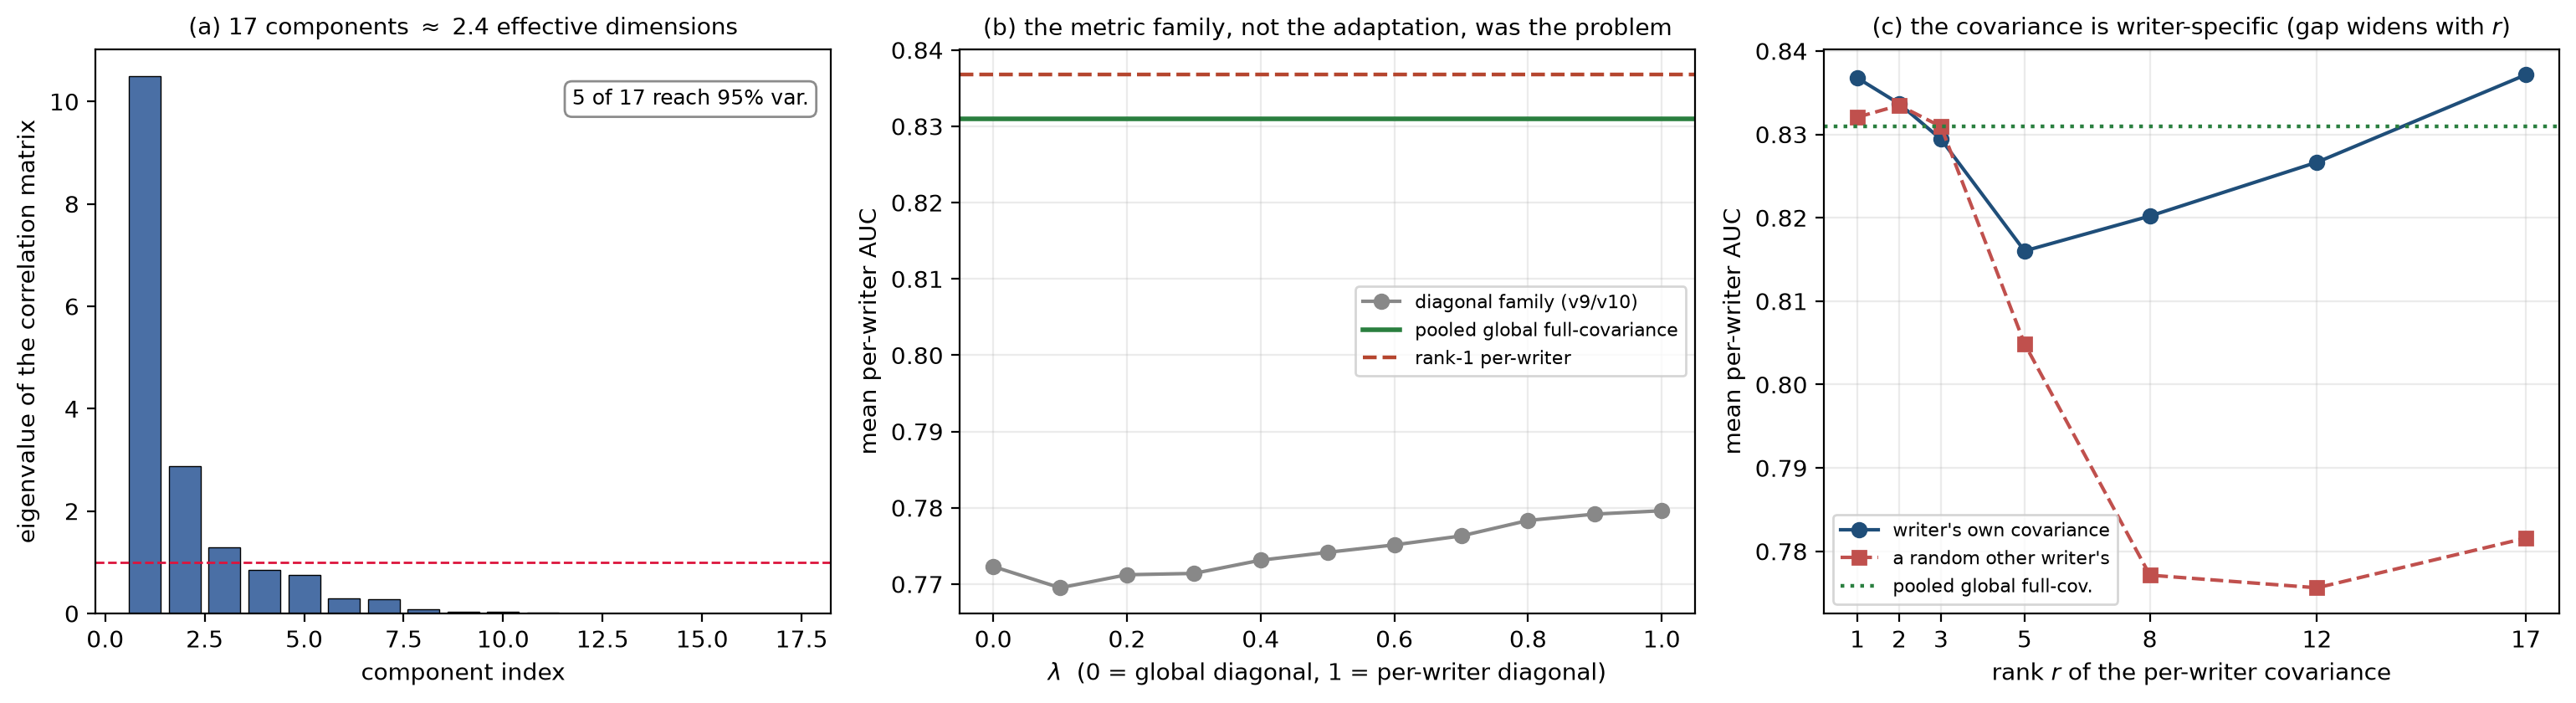

In [25]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.3))

# (a) component redundancy
ax[0].bar(np.arange(1, NDIM+1), ev, color="#4a6fa5", edgecolor="black", linewidth=0.5)
ax[0].axhline(1.0, color="crimson", ls="--", lw=1)
ax[0].set_xlabel("component index"); ax[0].set_ylabel("eigenvalue of the correlation matrix")
ax[0].set_title(f"(a) 17 components $\\approx$ {part_ratio:.1f} effective dimensions", fontsize=10)
ax[0].text(0.97, 0.93, f"{n95} of {NDIM} reach 95% var.", transform=ax[0].transAxes,
           ha="right", va="top", fontsize=9,
           bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="grey", alpha=0.9))

# (b) diagonal family is flat, covariance family is not
ax[1].plot(LAMBDA_GRID, SWEEP_ALL.mean(0), "o-", color="#888", label="diagonal family (v9/v10)")
ax[1].axhline(G_ALL.mean(), color="#2a7f3f", ls="-", lw=2, label="pooled global full-covariance")
ax[1].axhline(OWN_ALL[:, JR1].mean(), color="#b5452e", ls="--", lw=1.6, label="rank-1 per-writer")
ax[1].set_xlabel(r"$\lambda$  (0 = global diagonal, 1 = per-writer diagonal)")
ax[1].set_ylabel("mean per-writer AUC")
ax[1].set_title("(b) the metric family, not the adaptation, was the problem", fontsize=10)
ax[1].legend(fontsize=8, loc="center right"); ax[1].grid(alpha=0.25)

# (c) specificity: own vs permuted across rank
ax[2].plot(RANK_GRID, OWN_ALL.mean(0), "o-", color="#1f4e79", label="writer's own covariance")
ax[2].plot(RANK_GRID, OTH_ALL.mean(0), "s--", color="#c0504d", label="a random other writer's")
ax[2].axhline(G_ALL.mean(), color="#2a7f3f", ls=":", lw=1.6, label="pooled global full-cov.")
ax[2].set_xlabel("rank $r$ of the per-writer covariance"); ax[2].set_ylabel("mean per-writer AUC")
ax[2].set_title("(c) the covariance is writer-specific (gap widens with $r$)", fontsize=10)
ax[2].set_xticks(RANK_GRID); ax[2].legend(fontsize=8, loc="lower left"); ax[2].grid(alpha=0.25)

plt.tight_layout()
plt.savefig("v11_fig1_metric_family.png", dpi=200, bbox_inches="tight")
print("saved v11_fig1_metric_family.png")
plt.show()

from IPython.display import Image
Image(filename='v11_fig1_metric_family.png')

## 10 · Hypothesis table and machine-readable results

In [26]:
def verdict_row(name, a, b, direction="greater"):
    ps, ds = [], []
    for c in CORPORA:
        ps.append(wilcoxon(a(c), b(c)).pvalue); ds.append((a(c) - b(c)).mean())
    h = holm(ps)
    rej = [CORPORA[i] for i in range(len(CORPORA)) if h[i] < 0.05 and ds[i] > 0]
    d_all = np.concatenate([a(c) for c in CORPORA]) - np.concatenate([b(c) for c in CORPORA])
    m, lo, hi = boot_ci(d_all)
    return dict(test=name, pooled_d=float(round(m,4)), ci=[float(round(lo,4)), float(round(hi,4))],
                pooled_p=float(wilcoxon(np.concatenate([a(c) for c in CORPORA]),
                                        np.concatenate([b(c) for c in CORPORA])).pvalue),
                holm_rejected_on=rej, n_corpora_rejected=len(rej))

TABLE = [
 verdict_row("F3  pooled full-cov  >  global diagonal",      lambda c: AUC_G[c],        lambda c: AUC_B[c]),
 verdict_row("F4  own cov (r=17)   >  permuted writer",      lambda c: OWN[c][:,JR17],  lambda c: OTH[c][:,JR17]),
 verdict_row("F5  own cov (r=1)    >  pooled full-cov",      lambda c: OWN[c][:,JR1],   lambda c: AUC_G[c]),
 verdict_row("    own cov (r=17)   >  pooled full-cov",      lambda c: OWN[c][:,JR17],  lambda c: AUC_G[c]),
 verdict_row("    per-writer diag (v9 A) > global diag (B)", lambda c: AUC_A[c],        lambda c: AUC_B[c]),
]
print(f"{'test':48s}{'d':>9s}{'95% CI':>22s}{'pooled p':>11s}{'Holm-sig corpora':>20s}")
for t in TABLE:
    ci = f"[{t['ci'][0]:+.4f}, {t['ci'][1]:+.4f}]"
    print(f"{t['test']:48s}{t['pooled_d']:+9.4f}{ci:>22s}{t['pooled_p']:11.3g}"
          f"{(', '.join(t['holm_rejected_on']) or 'none'):>20s}")

RESULTS = dict(
    notebook="v11_covariance_metric", n_dev_writers=len(WKEYS), corpora=CORPORA,
    split_seed=SPLIT_SEED, nu=NU, gamma=GAMMA, n_enrol=N_ENROL,
    F1=F1, F2=F2,
    means={ "B_global_diagonal":   {c: float(AUC_B[c].mean()) for c in CORPORA},
            "A_perwriter_diagonal":{c: float(AUC_A[c].mean()) for c in CORPORA},
            "G_pooled_fullcov":    {c: float(AUC_G[c].mean()) for c in CORPORA},
            "own_rank1":           {c: float(OWN[c][:,JR1].mean())  for c in CORPORA},
            "own_rank17":          {c: float(OWN[c][:,JR17].mean()) for c in CORPORA},
            "permuted_rank17":     {c: float(OTH[c][:,JR17].mean()) for c in CORPORA} },
    tests=TABLE,
    oracle=(dict(global_=float(ORC_ALL[:,0].mean()), honest=float(ORC_ALL[:,1].mean()),
                 cheating_ceiling=float(ORC_ALL[:,2].mean())) if RUN_ORACLE else None),
)
with open("v11_results.json", "w") as f: json.dump(RESULTS, f, indent=2, default=float)
print("\nsaved v11_results.json")

test                                                    d                95% CI   pooled p    Holm-sig corpora
F3  pooled full-cov  >  global diagonal           +0.0586    [+0.0407, +0.0772]    8.3e-10      Bengali, Hindi
F4  own cov (r=17)   >  permuted writer           +0.0556    [+0.0272, +0.0854]   0.000754               Hindi
F5  own cov (r=1)    >  pooled full-cov           +0.0058    [+0.0036, +0.0081]   2.87e-06      Bengali, Hindi
    own cov (r=17)   >  pooled full-cov           +0.0062    [-0.0089, +0.0226]      0.836                none
    per-writer diag (v9 A) > global diag (B)      +0.0073    [-0.0027, +0.0177]      0.258                none

saved v11_results.json


## 11 · Confirmation run on the reserved writers

The 172 reserved writers are the project's only
untouched evaluation set. Every time they are read, the confidence of the final numbers drops, because
any design choice made after seeing them is a choice fitted to them.

The design to confirm is fixed: `G` (pooled global full-covariance) as the primary model, with rank-1
per-writer covariance as the adaptive variant, tested against the permuted-writer control.

In [27]:
if RUN_CONFIRMATION:
    print("CONFIRMATION RUN on reserved writers - this is a one-time, non-repeatable measurement.")
    DESC_R = build_descriptors(RESERVED, "v11_desc_reserved.npz")
    RK = sorted(DESC_R.keys())
    BYC_R = {c: [k for k in RK if k[0] == c] for c in sorted({k[0] for k in RK})}
    PART_R = {}
    for c, ks in BYC_R.items():
        for k in ks:
            r_ = np.random.RandomState(int(hashlib.md5(k[1].encode()).hexdigest()[:8], 16) % (2**31))
            o = k
            while o == k: o = ks[r_.randint(len(ks))]
            PART_R[k] = o
    # metrics estimated on each reserved writer's OWN enrolment; SIGMA_POOLED stays the dev-estimated one
    ZR = {k: (DESC_R[k][0] - DESC_R[k][0].mean(0)) / GLOBAL_SPREAD for k in RK}
    SR = {k: np.cov(ZR[k].T, bias=True) for k in RK}
    out = {c: [] for c in BYC_R}
    for k in RK:
        P, Qg, Qf = DESC_R[k]
        within = ZR[k].std(0) + EPS
        out[k[0]].append([auc_diag(P, Qg, Qf, GLOBAL_SPREAD),
                          auc_diag(P, Qg, Qf, GLOBAL_SPREAD * within),
                          auc_cov(P, Qg, Qf, SIGMA_POOLED),
                          auc_cov(P, Qg, Qf, rank_r_sigma(SR[k], 1)),
                          auc_cov(P, Qg, Qf, rank_r_sigma(SR[k], 17)),
                          auc_cov(P, Qg, Qf, rank_r_sigma(SR[PART_R[k]], 17))])
    OR = {c: np.array(out[c]) for c in out}
    NM = ["B diag", "A perwrt diag", "G pooled fullcov", "own r=1", "own r=17", "permuted r=17"]
    print(f"{'condition':22s}" + "".join(f"{c:>10s}" for c in OR) + f"{'ALL':>10s}")
    ALLR = np.vstack([OR[c] for c in OR])
    for j, nm in enumerate(NM):
        print(f"{nm:22s}" + "".join(f"{OR[c][:,j].mean():10.4f}" for c in OR) + f"{ALLR[:,j].mean():10.4f}")
    for a, b, lbl in [(2,0,"G > B"), (4,5,"own r=17 > permuted"), (3,2,"own r=1 > G")]:
        print(f"  {lbl:24s} d={ALLR[:,a].mean()-ALLR[:,b].mean():+.4f}  "
              f"p={wilcoxon(ALLR[:,a], ALLR[:,b]).pvalue:.4g}")
    np.savez("v11_confirmation.npz", **{c: OR[c] for c in OR}, names=np.array(NM))
else:
    print("RUN_CONFIRMATION = False. Reserved writers untouched - correct for now.")

RUN_CONFIRMATION = False. Reserved writers untouched - correct for now.


## 12 Final Words

**The contribution, stated precisely.** The study contributes a *metric-estimation layer* for one-class
signature verification operating on a pairwise dissimilarity representation, and an evaluation protocol
that separates two questions usually conflated in the literature: whether an adaptive metric is
**writer-specific** (permutation control) and whether it is **beneficial** (comparison against the
strongest global metric, not against a weak one).

**Three findings, in order of strength.**

1. *The dissimilarity representation is strongly correlated and the standard diagonal metric is
   mis-specified.* 17 components behave as ~2.4 effective dimensions. Replacing the diagonal metric with
   a pooled full-covariance metric gains +0.0586 AUC (95% CI [+0.040, +0.078], p = 8.3×10⁻¹⁰),
   Holm-significant on Bengali and Hindi. This is writer-independent and is the largest effect measured.

2. *A writer's covariance in this representation is genuinely writer-specific.* At full rank, a writer's
   own covariance outperforms a random other writer's by +0.0513 (p = 4.6×10⁻⁴), Holm-significant on
   Bengali and Hindi. This is a positive, controlled result about writer individuality in dissimilarity
   space.

3. *Converting that signal into accuracy is limited by estimation noise, and we quantify the limit.*
   The full-rank estimate does not beat the pooled metric (+0.0062, p = 0.84); a rank-1 estimate does,
   by +0.0058 (95% CI [+0.0036, +0.0081]), Holm-significant on Bengali and Hindi. An honest oracle
   reaches +0.0396 (p = 1.1×10⁻⁶), so roughly 85% of the available per-writer headroom remains
   uncaptured at n = 12 enrolled signatures.

*"What is actually new?"* New are: the metric-estimation layer, the finding that the representation's correlation structure dominates per-component
weighting, the permutation control that separates specificity from efficacy, and a measured upper bound
on what per-writer adaptation can deliver. *"Null and alternative hypothesis"* — every test above is
stated as H₁ (no difference) against H₂ (the named metric is better), tested by Wilcoxon signed-rank over
writers, Holm-corrected across the three corpora, with bootstrap intervals; Section 10 is the table.
*"Develop a model, do not compare two existing ones"* — the deliverable is the estimator in Section 6,
not a comparison of HOG against something else.

**Report the negative results.** v9's and v10's diagonal estimators are retained as ablations and
reported as refuted. A thesis that states what it refuted, with the controls that refuted it, defends far
better than one that only reports what worked.